# Simulasi Pertumbuhan Persentase Pengguna Internet di Indonesia Tahun 2000 sampai 2023

**Tugas Akhir 07 (TA-07)** | Pemodelan dan Simulasi
**Nama:** Aulia Nazwa Huriah | **NIM:** 301240010 | **Kelas:** 4B

**Dataset:** [Global Internet Usage by Country (2000-2023)](https://www.kaggle.com/datasets/meleknur/global-internet-usage-by-country-2000-2023) oleh meleknur di Kaggle, file `internet_usage.csv`.

Notebook ini mensimulasikan persentase penduduk Indonesia yang menggunakan internet memakai model pertumbuhan logistik. Parameter model dikalibrasi dengan data, divalidasi dengan metrik galat, lalu dipakai untuk eksperimen What-If.

## 1. Formulasi Model

**Struktur Stock-Flow**

| Komponen | Isi |
|---|---|
| Stock | $P(t)$ = persentase penduduk Indonesia yang menggunakan internet (%) |
| Inflow | pertambahan pengguna baru per tahun, yaitu $\frac{dP}{dt}$ |
| Outflow | tidak dimodelkan, karena data hanya mencatat persentase bersih |

**Feedback loop**

- **Reinforcing loop** (suku $rP$): makin banyak pengguna, makin banyak orang di sekitar mereka yang ikut memakai internet.
- **Balancing loop** (suku $1 - P/K$): makin mendekati batas jenuh, calon pengguna baru makin sedikit sehingga laju pertambahan melambat.

**Persamaan diferensial (model logistik)**

$$\frac{dP}{dt} = r\,P\left(1 - \frac{P}{K}\right)$$

**Solusi analitik** (dipakai untuk memeriksa ketelitian metode numerik)

$$P(t) = \frac{K}{1 + \left(\dfrac{K - P_0}{P_0}\right)e^{-r\,(t - t_0)}}$$

**Metode Euler** dengan langkah waktu $h$

$$P_{n+1} = P_n + h \cdot r\,P_n\left(1 - \frac{P_n}{K}\right)$$

**Parameter**

| Simbol | Arti | Nilai | Dasar penentuan |
|---|---|---|---|
| $P_0$ | persentase pengguna pada tahun awal | 0,9256 % | data tahun 2000 |
| $K$ | batas jenuh | 100 % | asumsi, batas atas sebuah persentase |
| $r$ | laju pertumbuhan | hasil kalibrasi | meminimalkan RMSE terhadap data |
| $t$ | waktu | 2000 sampai 2023 | satuan tahun |

**Asumsi:** $K$ tetap 100 %, $r$ konstan sepanjang waktu, dan tidak ada pengguna yang berhenti memakai internet.

## 2. Persiapan dan Eksplorasi Data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [2]:
# Unggah internet_usage.csv jika dijalankan di Google Colab
if not os.path.exists("internet_usage.csv"):
    from google.colab import files
    files.upload()

df_raw = pd.read_csv("internet_usage.csv")

# Ambil baris Indonesia, lalu ubah dari format lebar (satu kolom per tahun) menjadi dua kolom
row = df_raw[df_raw["Country Name"] == "Indonesia"].iloc[0, 2:]

df = pd.DataFrame({
    "Time": row.index.astype(float),
    "Pengguna": pd.to_numeric(row.values, errors="coerce")   # tanda ".." menjadi NaN
})

df.head()

,Time,Pengguna
0,2000.0,0.925564
1,2001.0,2.018610
2,2002.0,2.134140
3,2003.0,2.387020
4,2004.0,2.600290


In [3]:
print("Ukuran data    :", df.shape)
print("Missing value  :", df["Pengguna"].isna().sum())
print("Tipe data      :")
print(df.dtypes)
df["Pengguna"].describe()

Ukuran data    : (24, 2)
Missing value  : 0
Tipe data      :
Time        float64
Pengguna    float64
dtype: object


count    24.000000
mean     21.992688
std      22.449541
min       0.925564
25%       4.474112
50%      13.400000
75%      34.228000
max      69.208400
Name: Pengguna, dtype: float64

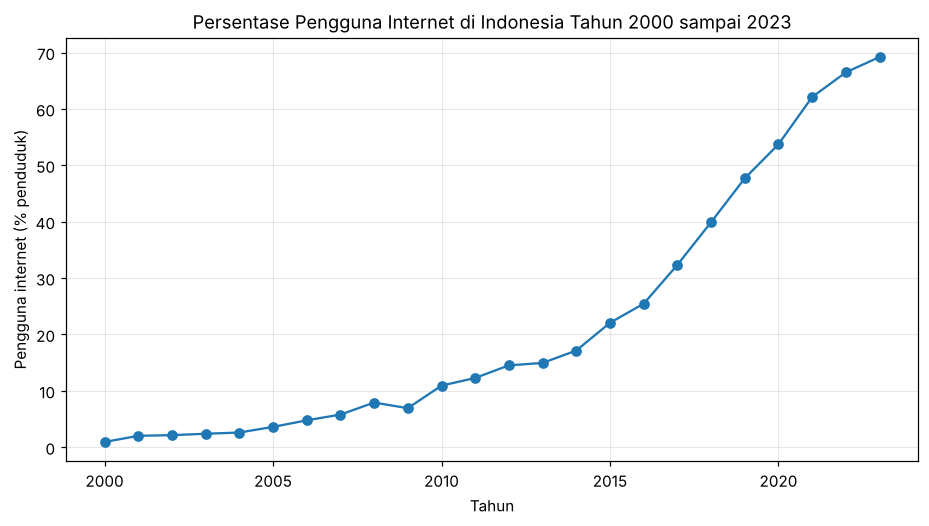

In [4]:
plt.figure(figsize=(10, 5))
plt.plot(df["Time"], df["Pengguna"], marker="o", color="tab:blue")
plt.title("Persentase Pengguna Internet di Indonesia Tahun 2000 sampai 2023")
plt.xlabel("Tahun")
plt.ylabel("Pengguna internet (% penduduk)")
plt.show()

**Interpretasi data**

- Data terdiri dari 24 baris (tahun 2000 sampai 2023) dan 2 kolom, tanpa nilai yang hilang.
- Persentase naik dari 0,93 % pada 2000 menjadi 69,21 % pada 2023. Rata-ratanya 21,99 % dan mediannya 13,40 %.
- Pertumbuhan awal sangat lambat. Pada 2004 persentasenya baru 2,60 %.
- Kenaikan tahunan paling besar terjadi pada 2021 (8,38 poin). Setelah itu kenaikannya mengecil menjadi 4,38 poin pada 2022 dan 2,72 poin pada 2023.
- Pola ini membentuk kurva S, sehingga model logistik masuk akal untuk dipakai.
- Ada satu penurunan kecil pada 2009 (dari 7,92 % menjadi 6,92 %). Model logistik tidak bisa menirunya.

## 3. Implementasi Simulasi

In [5]:
# Data dan kondisi awal
t_data = df["Time"].values
y_data = df["Pengguna"].values

P0 = y_data[0]          # kondisi awal (tahun 2000)
K = 100.0               # batas jenuh (asumsi)
t0, t1 = t_data[0], t_data[-1]


def logistic_model(t, P, r, K):
    # Persamaan diferensial logistik: dP/dt = r P (1 - P/K)
    return r * P * (1 - P / K)


def simulasi_solve_ivp(r, K, P0, t_eval):
    # Solusi numerik memakai solver SciPy
    sol = solve_ivp(logistic_model, (t_eval[0], t_eval[-1]), [P0],
                    args=(r, K), t_eval=t_eval, rtol=1e-8, atol=1e-10)
    return sol.y[0]


def simulasi_euler(r, K, P0, t_awal, t_akhir, h):
    # Solusi numerik memakai metode Euler dengan langkah waktu h
    n = int(round((t_akhir - t_awal) / h))
    waktu = t_awal + h * np.arange(n + 1)
    P = np.empty(n + 1)
    P[0] = P0
    for i in range(n):
        P[i + 1] = P[i] + h * r * P[i] * (1 - P[i] / K)
    return waktu, P


def solusi_analitik(t, r, K, P0, t_awal):
    return K / (1 + ((K - P0) / P0) * np.exp(-r * (t - t_awal)))


def hitung_metrik(y_asli, y_sim):
    galat = y_sim - y_asli
    rmse = np.sqrt(np.mean(galat ** 2))
    mae = np.mean(np.abs(galat))
    r2 = 1 - np.sum(galat ** 2) / np.sum((y_asli - y_asli.mean()) ** 2)
    return rmse, mae, r2

In [6]:
# Kalibrasi r: cari nilai r yang meminimalkan RMSE antara simulasi dan data
def rmse_untuk_r(r):
    return hitung_metrik(y_data, simulasi_solve_ivp(r, K, P0, t_data))[0]


hasil = minimize_scalar(rmse_untuk_r, bounds=(0.01, 1.0), method="bounded")
r_hat = hasil.x

print(f"P0 (tahun 2000)    : {P0:.4f} %")
print(f"K (asumsi)         : {K:.0f} %")
print(f"r hasil kalibrasi  : {r_hat:.4f} per tahun")
print(f"RMSE minimum       : {hasil.fun:.4f} poin persentase")

P0 (tahun 2000)    : 0.9256 %
K (asumsi)         : 100 %
r hasil kalibrasi  : 0.2385 per tahun
RMSE minimum       : 1.9397 poin persentase


## 4. Validasi Model (Baseline vs Data)

In [7]:
# Baseline: tiga cara menghitung model yang sama
y_ivp = simulasi_solve_ivp(r_hat, K, P0, t_data)

T_e1, P_e1 = simulasi_euler(r_hat, K, P0, t0, t1, 1.0)
y_e1 = P_e1

T_e01, P_e01 = simulasi_euler(r_hat, K, P0, t0, t1, 0.1)
y_e01 = P_e01[np.round((t_data - t0) / 0.1).astype(int)]

tabel_metrik = pd.DataFrame(
    [hitung_metrik(y_data, y_ivp),
     hitung_metrik(y_data, y_e1),
     hitung_metrik(y_data, y_e01)],
    columns=["RMSE", "MAE", "R2"],
    index=["solve_ivp", "Euler h=1", "Euler h=0.1"]
).round(4)
tabel_metrik

,RMSE,MAE,R2
solve_ivp,1.9397,1.5007,0.9922
Euler h=1,5.6761,4.0102,0.9333
Euler h=0.1,1.9828,1.5763,0.9919


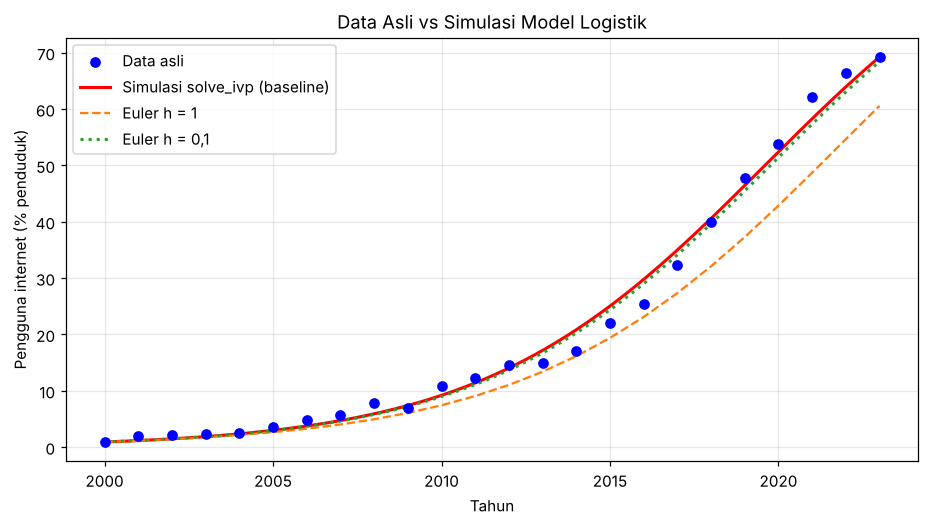

In [8]:
t_halus = np.linspace(t0, t1, 300)

plt.figure(figsize=(10, 5))
plt.scatter(t_data, y_data, color="blue", label="Data asli", zorder=3)
plt.plot(t_halus, simulasi_solve_ivp(r_hat, K, P0, t_halus), color="red", linewidth=2,
         label="Simulasi solve_ivp (baseline)")
plt.plot(T_e1, P_e1, color="tab:orange", linestyle="--", label="Euler h = 1")
plt.plot(T_e01, P_e01, color="tab:green", linestyle=":", linewidth=2, label="Euler h = 0,1")
plt.title("Data Asli vs Simulasi Model Logistik")
plt.xlabel("Tahun")
plt.ylabel("Pengguna internet (% penduduk)")
plt.legend()
plt.show()

**Interpretasi**

- Model dengan $r = 0{,}2385$ dan $K = 100$ mengikuti pola data dengan baik. Hasil `solve_ivp` memberi RMSE 1,94 poin, MAE 1,50 poin, dan $R^2 = 0{,}9922$.
- Euler dengan $h = 1$ tertinggal dari data (RMSE 5,68 poin), sedangkan Euler dengan $h = 0{,}1$ hampir menempel pada `solve_ivp` (RMSE 1,98 poin).
- Garis simulasi tidak pernah berhimpit sempurna dengan data karena model hanya punya satu mekanisme dan dua parameter, sedangkan data nyata dipengaruhi banyak hal lain.

In [9]:
# Ketelitian metode numerik terhadap solusi analitik (rumus pasti dari model)
galat_ivp = y_ivp - solusi_analitik(t_data, r_hat, K, P0, t0)
galat_e1 = P_e1 - solusi_analitik(T_e1, r_hat, K, P0, t0)
galat_e01 = P_e01 - solusi_analitik(T_e01, r_hat, K, P0, t0)

for nama, g in [("solve_ivp", galat_ivp), ("Euler h=1", galat_e1), ("Euler h=0.1", galat_e01)]:
    print(f"{nama:12s} RMSE = {np.sqrt(np.mean(g**2)):.7f} | galat maksimum = {np.max(np.abs(g)):.7f}")

print()
print(f"Tahun 2023 -> analitik: {solusi_analitik(t1, r_hat, K, P0, t0):.2f} % | Euler h=1: {P_e1[-1]:.2f} %")

solve_ivp    RMSE = 0.0000004 | galat maksimum = 0.0000013
Euler h=1    RMSE = 5.3723653 | galat maksimum = 9.5836250
Euler h=0.1  RMSE = 0.5681565 | galat maksimum = 0.9832832

Tahun 2023 -> analitik: 69.25 % | Euler h=1: 60.58 %


**Interpretasi**

- Galat maksimum `solve_ivp` terhadap solusi analitik hanya 0,0000013 poin, jadi solver SciPy bisa dianggap benar-benar akurat untuk model ini.
- Euler dengan $h = 1$ punya galat maksimum 9,58 poin. Setelah $h$ diperkecil 10 kali menjadi 0,1, galat maksimumnya turun menjadi 0,98 poin. Artinya galat Euler mengecil kira-kira sebanding dengan $h$.
- Pada 2023, Euler dengan $h = 1$ hanya mencapai 60,58 %, padahal solusi analitiknya 69,25 %. Pada fase naik cepat, satu langkah besar memakai kemiringan di awal langkah sehingga hasilnya tertinggal.

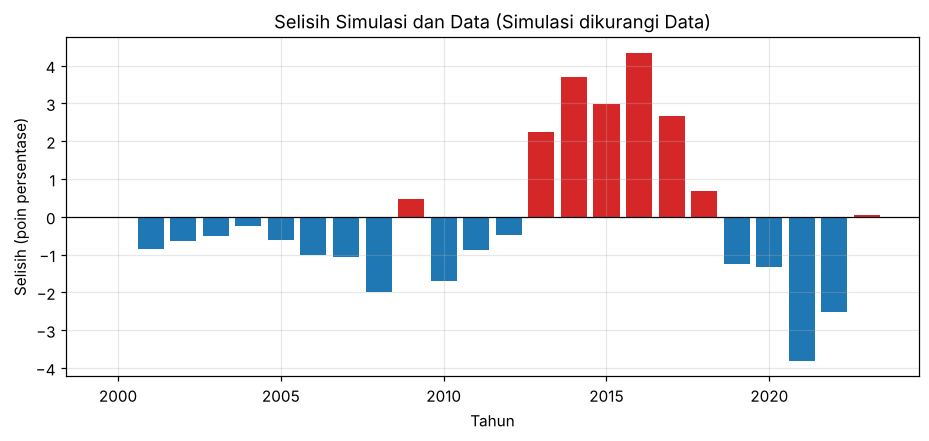

Simulasi paling di atas data : tahun 2016 (+4.34 poin)
Simulasi paling di bawah data: tahun 2021 (-3.81 poin)


In [10]:
# Pola selisih antara simulasi dan data (positif = simulasi lebih tinggi dari data)
selisih = y_ivp - y_data

plt.figure(figsize=(10, 4))
warna = np.where(selisih >= 0, "tab:red", "tab:blue")
plt.bar(t_data, selisih, color=warna)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Selisih Simulasi dan Data (Simulasi dikurangi Data)")
plt.xlabel("Tahun")
plt.ylabel("Selisih (poin persentase)")
plt.show()

print(f"Simulasi paling di atas data : tahun {t_data[selisih.argmax()]:.0f} ({selisih.max():+.2f} poin)")
print(f"Simulasi paling di bawah data: tahun {t_data[selisih.argmin()]:.0f} ({selisih.min():+.2f} poin)")

**Interpretasi**

- Simulasi lebih tinggi dari data pada 2013 sampai 2018 dengan selisih terbesar 4,34 poin pada 2016. Artinya pertumbuhan data waktu itu lebih lambat dari yang diminta model.
- Setelah itu data mengejar dengan kenaikan 6,04 sampai 8,38 poin per tahun pada 2017 sampai 2021, sehingga simulasi menjadi lebih rendah dari data pada 2019 sampai 2022 dengan selisih terbesar $-3{,}81$ poin pada 2021.
- Model logistik bersifat simetris dan mulus, jadi tidak bisa meniru percepatan mendadak ini maupun penurunan kecil pada 2009. Ini bagian dari keterbatasan model.
- Titik belok model (saat $P = K/2$) jatuh pada tahun 2019,6. Di data, nilai 50 % terlewati antara 2019 (47,69 %) dan 2020 (53,73 %), jadi waktunya cocok.

In [11]:
# Kepekaan terhadap asumsi K: kalibrasi ulang r untuk beberapa nilai K
baris = []
for K_uji in (80, 90, 100):
    hsl = minimize_scalar(
        lambda r: hitung_metrik(y_data, simulasi_solve_ivp(r, K_uji, P0, t_data))[0],
        bounds=(0.01, 1.0), method="bounded")
    rmse, mae, r2 = hitung_metrik(y_data, simulasi_solve_ivp(hsl.x, K_uji, P0, t_data))
    baris.append([K_uji, hsl.x, rmse, mae, r2])

pd.DataFrame(baris, columns=["K", "r terkalibrasi", "RMSE", "MAE", "R2"]).round(4)

,K,r terkalibrasi,RMSE,MAE,R2
0,80,0.2517,3.3101,2.3928,0.9773
1,90,0.2443,2.4642,1.8515,0.9874
2,100,0.2385,1.9397,1.5007,0.9922


**Interpretasi**

- Makin besar $K$, makin kecil galatnya. RMSE turun dari 3,31 (K = 80) menjadi 2,46 (K = 90) dan 1,94 (K = 100).
- Data baru mencapai 69,21 % pada 2023 dan belum menunjukkan tanda jenuh, sehingga data tidak bisa menentukan nilai $K$ dengan sendirinya.
- Karena itu $K = 100$ dipilih sebagai asumsi yang masuk akal, yaitu batas atas sebuah persentase. Ini harus ditulis sebagai asumsi di laporan, bukan hasil estimasi.

## 5. Eksperimen Skenario (What-If)

In [12]:
# Waktu simulasi diperpanjang sampai 2035 dengan langkah 0,01 tahun
t_sim = np.linspace(2000, 2035, 3501)


def tahun_capai(P, ambang):
    # Tahun pertama saat P mencapai ambang. NaN jika tidak tercapai.
    ada = P >= ambang
    return t_sim[np.argmax(ada)] if ada.any() else np.nan


def ringkas(nama, r, K_skenario):
    P = simulasi_solve_ivp(r, K_skenario, P0, t_sim)
    ambil = lambda tahun: P[int(round((tahun - 2000) / 0.01))]
    rmse_data = hitung_metrik(y_data, simulasi_solve_ivp(r, K_skenario, P0, t_data))[0]

    def fmt(x):
        return "tidak tercapai" if np.isnan(x) else f"{x:.1f}"

    return P, {
        "Skenario": nama, "r": round(r, 4), "K": K_skenario,
        "P 2023 (%)": round(ambil(2023), 2), "P 2035 (%)": round(ambil(2035), 2),
        "Tahun capai 50%": fmt(tahun_capai(P, 50)),
        "Tahun capai 80%": fmt(tahun_capai(P, 80)),
        "Tahun capai 90%": fmt(tahun_capai(P, 90)),
        "RMSE vs data": round(rmse_data, 2),
    }

### Eksperimen 1: Laju pertumbuhan $r$ berubah 20 %

Skenario ini bertanya: bagaimana jika sejak tahun 2000 penyebaran internet 20 % lebih cepat (misalnya akses dan perangkat lebih mudah didapat) atau 20 % lebih lambat? Perubahan $r$ diterapkan sepanjang periode, jadi ini pengandaian dan kurvanya memang akan menjauh dari data asli.

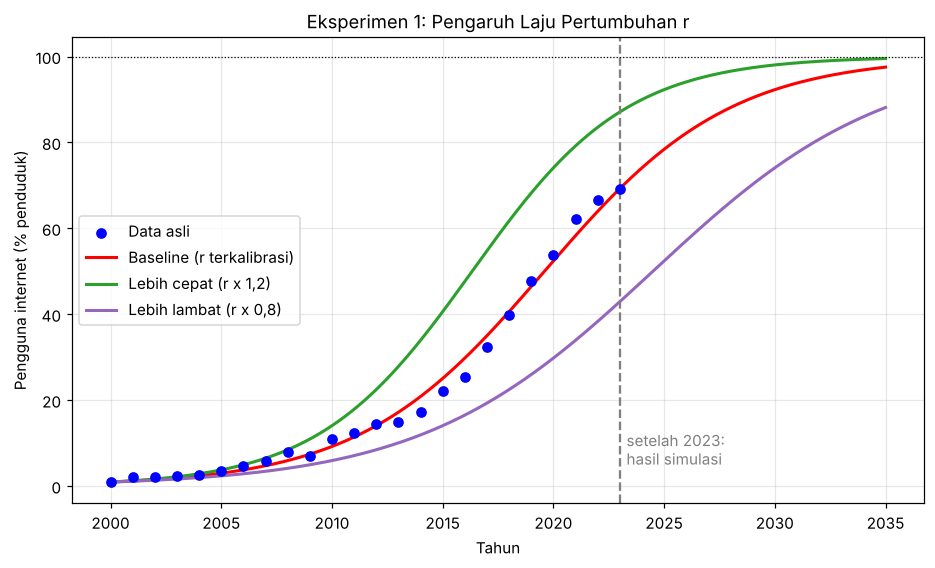

,Skenario,r,K,P 2023 (%),P 2035 (%),Tahun capai 50%,Tahun capai 80%,Tahun capai 90%,RMSE vs data
0,Baseline (r terkalibrasi),0.2385,100.0,69.25,97.52,2019.6,2025.4,2028.8,1.94
1,"Lebih cepat (r x 1,2)",0.2862,100.0,87.09,99.52,2016.3,2021.2,2024.0,13.11
2,"Lebih lambat (r x 0,8)",0.1908,100.0,42.92,88.12,2024.5,2031.8,tidak tercapai,13.09


In [13]:
daftar_r = [("Baseline (r terkalibrasi)", r_hat),
            ("Lebih cepat (r x 1,2)", r_hat * 1.2),
            ("Lebih lambat (r x 0,8)", r_hat * 0.8)]
warna_r = ["red", "tab:green", "tab:purple"]

ringkasan_1 = []
plt.figure(figsize=(10, 5.5))
plt.scatter(t_data, y_data, color="blue", label="Data asli", zorder=3)
for (nama, r_skn), warna in zip(daftar_r, warna_r):
    P, baris = ringkas(nama, r_skn, K)
    ringkasan_1.append(baris)
    plt.plot(t_sim, P, color=warna, linewidth=2, label=nama)

plt.axvline(2023, color="gray", linestyle="--")
plt.text(2023.3, 5, "setelah 2023:\nhasil simulasi", color="gray")
plt.axhline(K, color="black", linestyle=":", linewidth=0.8)
plt.title("Eksperimen 1: Pengaruh Laju Pertumbuhan r")
plt.xlabel("Tahun")
plt.ylabel("Pengguna internet (% penduduk)")
plt.legend(loc="center left")
plt.show()

pd.DataFrame(ringkasan_1)

**Interpretasi**

- Jika $r$ naik 20 %, persentase pengguna pada 2023 mencapai 87,09 %. Jika $r$ turun 20 %, hanya 42,92 %. Baselinenya 69,25 %, dekat dengan data asli 69,21 %.
- Titik 50 % tercapai pada 2016,3 untuk skenario cepat, 2019,6 untuk baseline, dan 2024,5 untuk skenario lambat. Jadi perubahan $r$ sebesar 20 % menggeser waktunya sekitar 3,3 tahun lebih awal atau 4,9 tahun lebih lambat.
- Bentuk kurvanya tetap S pada ketiga skenario. Yang berubah hanya kecepatan menuju batas jenuh, karena balancing loop $(1 - P/K)$ sama-sama membatasi pertumbuhan.
- Kedua skenario menjauh dari data asli dengan RMSE sekitar 13 poin (13,11 dan 13,09), jauh di atas baseline yang 1,94 poin. Ini menunjukkan model sangat peka terhadap $r$, sehingga kalibrasi $r$ adalah langkah yang penting.
- Pada 2035 ketiga skenario sudah di atas 88 %. Skenario lambat paling akhir mendekati jenuh, sedangkan skenario cepat sudah hampir 100 % (99,52 %).
- Nilai setelah 2023 adalah hasil simulasi di bawah asumsi $K = 100$ dan $r$ konstan, bukan prediksi resmi.

### Eksperimen 2: Batas jenuh $K$ lebih rendah

Karena $K$ adalah asumsi paling lemah, eksperimen ini menguji bagaimana jika tidak semua penduduk akan memakai internet, misalnya batas jenuhnya 90 %. Nilai $r$ dibiarkan sama dengan baseline.

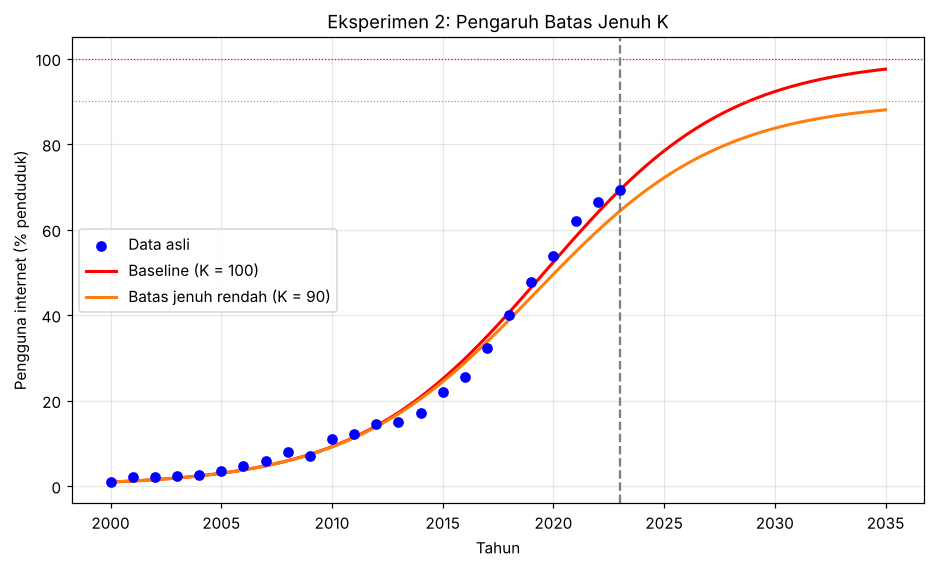

,Skenario,r,K,P 2023 (%),P 2035 (%),Tahun capai 50%,Tahun capai 80%,Tahun capai 90%,RMSE vs data
0,Baseline (K = 100),0.2385,100.0,69.25,97.52,2019.6,2025.4,2028.8,1.94
1,Batas jenuh rendah (K = 90),0.2385,90.0,64.32,87.99,2020.1,2027.9,tidak tercapai,2.89


In [14]:
daftar_k = [("Baseline (K = 100)", 100.0), ("Batas jenuh rendah (K = 90)", 90.0)]
warna_k = ["red", "tab:orange"]

ringkasan_2 = []
plt.figure(figsize=(10, 5.5))
plt.scatter(t_data, y_data, color="blue", label="Data asli", zorder=3)
for (nama, K_skn), warna in zip(daftar_k, warna_k):
    P, baris = ringkas(nama, r_hat, K_skn)
    ringkasan_2.append(baris)
    plt.plot(t_sim, P, color=warna, linewidth=2, label=nama)
    plt.axhline(K_skn, color=warna, linestyle=":", linewidth=0.8)

plt.axvline(2023, color="gray", linestyle="--")
plt.title("Eksperimen 2: Pengaruh Batas Jenuh K")
plt.xlabel("Tahun")
plt.ylabel("Pengguna internet (% penduduk)")
plt.legend(loc="center left")
plt.show()

pd.DataFrame(ringkasan_2)

**Interpretasi**

- Pada fase awal kedua kurva hampir sama, karena saat $P$ masih kecil suku $(1 - P/K)$ mendekati 1 untuk $K$ berapa pun.
- Perbedaan muncul saat $P$ makin besar. Pada 2023 hasilnya 64,32 % untuk $K = 90$ dan 69,25 % untuk $K = 100$.
- Dengan $K = 90$, titik 50 % tercapai pada 2020,1, hanya sekitar 0,5 tahun lebih lambat dari baseline. Namun kurvanya melandai di bawah 90 %, dan pada 2035 baru 87,99 %, sedangkan baseline sudah 97,52 %.
- Jadi $K$ menentukan nilai akhir sistem, sedangkan $r$ menentukan seberapa cepat nilai itu dicapai.
- Dengan $r$ yang sama, $K = 90$ memberi RMSE 2,89 poin terhadap data, lebih besar dari baseline yang 1,94 poin. Jadi data sampai 2023 lebih mendukung baseline, tetapi selisihnya tidak besar sehingga nilai $K$ tetap tidak bisa dipastikan dari data.

## 6. Kesimpulan

**Apakah model berhasil meniru fenomena nyata?** Ya, secara umum. Model logistik dengan $r = 0{,}2385$ per tahun dan $K = 100$ % menghasilkan RMSE 1,94 poin dan $R^2 = 0{,}9922$ terhadap data 2000 sampai 2023. Titik belok model (2019,6) juga sesuai dengan data.

**Keterbatasan**

1. $K = 100$ adalah asumsi. Data belum jenuh, sehingga galat terus mengecil saat $K$ dinaikkan dan nilai $K$ tidak bisa diestimasi dari data.
2. $r$ dianggap konstan, padahal data punya periode lambat (2013 sampai 2018) dan periode lonjakan (2017 sampai 2021) yang tidak bisa ditiru model.
3. Penurunan kecil pada 2009 tidak bisa muncul di model logistik, karena $P$ selalu naik selama $0 < P < K$.
4. Data berasal dari satu dataset Kaggle. Angka bisa berbeda dengan sumber lain yang memakai definisi pengguna internet yang berbeda.
5. Hasil setelah 2023 adalah simulasi di bawah asumsi model, bukan prediksi resmi.